# 12 Network models

## Preferential growth and comparing network models

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for sections 12.5 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

A network need not be constructed all at once: new nodes can arrive and
preferentially connect to already well-connected nodes.

**Seminal reading:** Barabási & Albert (1999),
[*Emergence of scaling in random networks*](https://doi.org/10.1126/science.286.5439.509),
*Science* **286**, 509–512. 

## 12.5 Albert–Barabási preferential-growth graphs

Parameters:

- $n_0$: number of mutually connected initial nodes
- $m$: number of links when adding a node
- $n$: final number of nodes

Add one new node at a time with $m$ links to distinct existing nodes, chosen with probability proportional to degree: 

$$p_i=\frac{k_i}{\sum_j k_j}$$

Note: the probability should be computed again each step.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path
import sys
sys.path.insert(0, "../12_modules")

import network_models as nm
import nm_visualize as vis

Let's examine how such a network is formed, step by step:

In [2]:
n0 = 5
m = 3

rng = np.random.default_rng()
G_ba = nx.complete_graph(n0)
print("Initial degrees:", dict(G_ba.degree()))

Initial degrees: {0: 4, 1: 4, 2: 4, 3: 4, 4: 4}


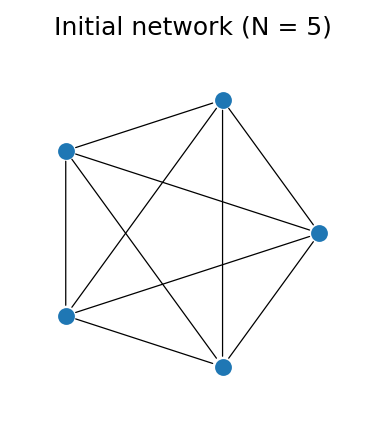

In [3]:
# Visualize the initial network
fig, ax = plt.subplots(figsize=(3, 3), dpi=150)

vis.draw_network_dots(G_ba, ax=ax)

ax.set_title(f"Initial network (N = {n0})", fontsize=12)
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()

Let's add the first new node. 

We need to check the propabilities of attachment:

In [4]:
first_new_node = n0

degrees_before = np.array(
    [G_ba.degree(i) for i in range(first_new_node)],
    dtype=float)

probabilities = degrees_before / degrees_before.sum()

targets = rng.choice(
    first_new_node, size=m, replace=False, p=probabilities
)

print("Attachment probabilities:", probabilities)

print("Selected targets:", targets)

Attachment probabilities: [0.2 0.2 0.2 0.2 0.2]
Selected targets: [1 0 4]


In [5]:
G_ba.add_node(first_new_node)

for target in targets:
    G_ba.add_edge(first_new_node, int(target))
    
print("New node degree:", G_ba.degree(first_new_node))

New node degree: 3


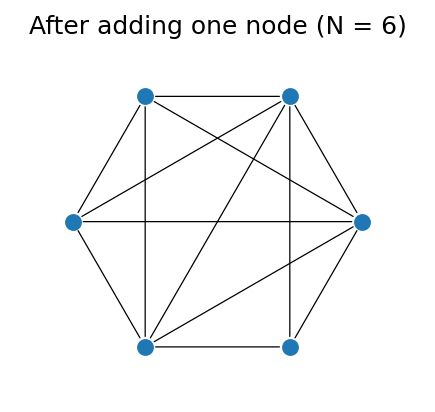

Updated degrees: {0: 5, 1: 5, 2: 4, 3: 4, 4: 5, 5: 3}


In [6]:
# Visualize the updated network
fig, ax = plt.subplots(figsize=(3, 3), dpi=150)

vis.draw_network_dots(G_ba, ax=ax)

ax.set_title("After adding one node (N = 6)", fontsize=12)
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()

print("Updated degrees:", dict(G_ba.degree()))

Final nodes: 50
Final edges: 145


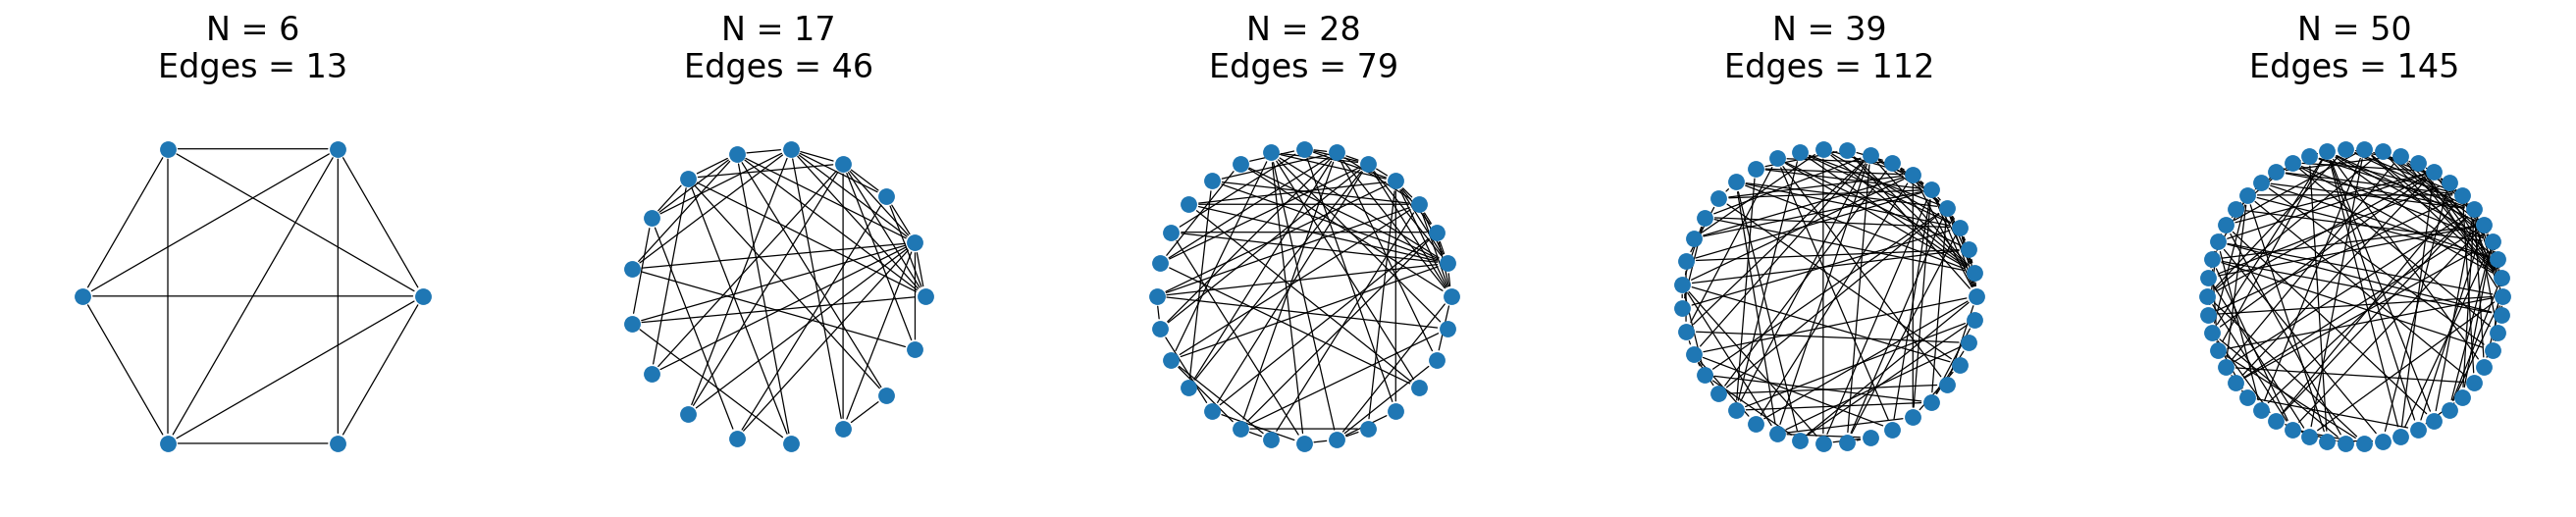

In [7]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path
import sys

sys.path.insert(0, "../12_modules")

import network_models as nm
import nm_visualize as vis

# -----------------------------------
# 1. Parameters
# -----------------------------------

n0 = 6
n_final = 50
m = 3

# -----------------------------------
# 2. Snapshot sizes
# -----------------------------------

snapshot_sizes = np.linspace(n0, n_final, 5, dtype=int).tolist()

snapshots = {n0: G_ba.copy()}

# -----------------------------------
# 3. Grow the network
# -----------------------------------

for new_node in range(n0, n_final):

    # Degrees of existing nodes
    existing_degrees = np.array(
        [G_ba.degree(j) for j in range(new_node)],
        dtype=float
    )

    # Preferential attachment probabilities
    weights = existing_degrees / existing_degrees.sum()

    # Select m distinct existing nodes
    targets = rng.choice(
        new_node,
        size=m,
        replace=False,
        p=weights
    )

    # Add new node and edges
    G_ba.add_node(new_node)

    for target in targets:
        G_ba.add_edge(new_node, int(target))

    # Save network at selected sizes
    if G_ba.number_of_nodes() in snapshot_sizes:
        snapshots[G_ba.number_of_nodes()] = G_ba.copy()

print("Final nodes:", G_ba.number_of_nodes())
print("Final edges:", G_ba.number_of_edges())

# -----------------------------------
# 4. Plot network evolution
# -----------------------------------

fig, axes = plt.subplots(
    1,
    len(snapshots),
    figsize=(18, 3.5),
    dpi=150
)

for ax, (n, G) in zip(axes, snapshots.items()):

    vis.draw_network_dots(G, ax=ax)

    ax.set_title(
        f"N = {n}\nEdges = {G.number_of_edges()}",
        fontsize=16
    )

plt.tight_layout()
plt.show()

**Degree distributions** and the power-law tail

In [8]:
n_large = 1000
m_large = 3
seed_size = 5

G_large = nm.preferential_growth(
    n_large, m_large, n0=seed_size
)

large_degrees = np.array([d for _, d in G_large.degree()])
unique_degrees = np.unique(large_degrees)

ccdf = np.array([np.mean(large_degrees >= k) for k in unique_degrees])

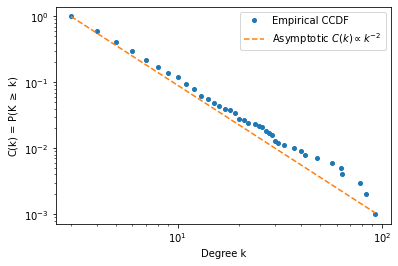

In [9]:
plt.loglog(unique_degrees, ccdf, "o", markersize=4,
           label="Empirical CCDF")
k_theory = np.arange(m_large, large_degrees.max() + 1)
plt.loglog(k_theory, (m_large / k_theory)**2, "--",
           label=r"Asymptotic $C(k) \propto k^{-2}$")
plt.xlabel("Degree k")
plt.ylabel(r"C(k) = P(K $\geq$ k)")
plt.legend()
plt.show()

### Exercise 12.6

- Path length versus network size $n$
- Clustering coefficient versus $m$. 


Let's simualte the mean path length versus network size $n$

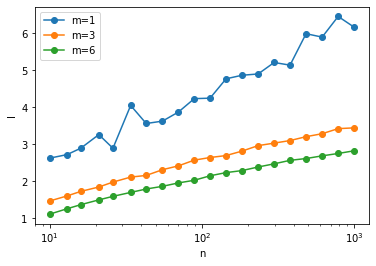

In [10]:
n_sizes = np.unique(
    np.round(np.geomspace(10, 1000, 20), 0)
).astype(int)
m_values = [1, 3, 6]

for edge_count in m_values:
    distances = []
    for size in n_sizes:
        graph = nm.preferential_growth(
            size, edge_count, n0=edge_count + 2
        )
        distances.append(nx.average_shortest_path_length(graph))
    plt.plot(n_sizes, distances, "o-", label=f"m={edge_count}")
    
plt.xlabel("n")
plt.xscale("log")
plt.ylabel("l")
plt.legend()
plt.show()

Let's simulate the clustering versus $m$

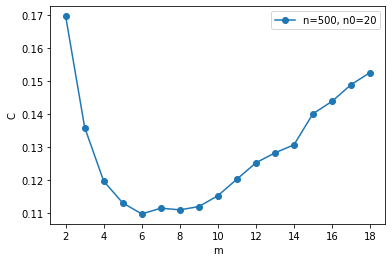

In [11]:
n = 500
n_0 = 20

m_values = np.arange(2, n_0 - 1).astype(int)

C = []
for edge_count in m_values:    
    graph = nm.preferential_growth(
            n, edge_count, n0=n_0
        )
    C.append(nx.transitivity(graph))

plt.plot(m_values, C, "o-", label=f"n={n}, n0={n_0}")

plt.xlabel("m")
plt.ylabel("C")
plt.legend()
plt.show()

<a id="questions"></a>
## Questions

- [Q9: Preferential attachment](#q9)

- [Q10: Degrees distribution](#q10)

- [Q11: Average path length and clustering coefficient](#q11)

<a id="q9"></a>
### Q9: Preferential attachment

[Go back to questions](#questions)

Refer to **Section 12.5, "Albert–Barabási preferential-growth graphs"**, where the notebook starts with `n0 = 5`, `m = 3`, and `n_final = 35`.

**a.** The notebook initializes the network using:

    G_ba = nx.complete_graph(n0)

What are the degrees of the five initial nodes? Why are their attachment probabilities initially equal?

**b.** Suppose the first new node (node 5) connects to nodes 0, 2, and 4. Calculate the new degrees of all six nodes. Which existing nodes are now more likely to receive a connection from the next new node? Explain.

**c.** In the code that adds new nodes, the attachment probabilities are recalculated at every step:

    weights = existing_degrees / existing_degrees.sum()

What would happen if the notebook continued using the initial attachment probabilities instead? Would the resulting network still follow the same preferential-growth rule? Explain.



<a id="q10"></a>
### Q10: Degrees distribution

[Go back to questions](#questions)

Refer to **Section 12.5, "Degree distributions and the power-law tail"**, where the notebook generates a network with `n_large = 1000`, `m_large = 3`, and `seed_size = 5`.

**a.** The notebook calculates:

    ccdf = np.array([np.mean(large_degrees >= k) for k in unique_degrees])

Suppose a small network has node degrees `[2, 2, 3, 3, 4, 8]`. What would this expression give for `k = 3` and `k = 4`? Explain what these values represent.

**b.** The notebook plots the degree distribution using:

    plt.loglog(unique_degrees, ccdf, "o")

Why are logarithmic scales used on both axes? What does an approximately straight line in this plot suggest about the degree distribution?

**c.** Suppose the network is generated with `m_large = 5` instead of `m_large = 3`, keeping `n_large = 1000` and `seed_size = 5` unchanged. How would this affect the number of edges and the mean degree of the network? Explain.



<a id="q11"></a>
### Q11: Average path length and clustering coefficient

[Go back to questions](#questions)

Refer to **Exercise 12.6 in Section 12.5**, where the notebook investigates the mean shortest-path length as a function of network size `n` and the clustering coefficient `C` as a function of `m`.

**a.** The notebook calculates mean shortest-path lengths for:

    m_values = [1, 3, 6]

For a fixed network size `n`, which value of `m` would you generally expect to produce the shortest mean path length? Explain why.

**b.** In Exercise 12.6, the notebook calculates the mean shortest-path length for networks of increasing size `n`. Keeping `m` fixed, how would you expect the mean shortest-path length to change as the network grows? Why might this increase be relatively slow in a preferential-growth network?

**c.** The clustering plot shows that `C` first decreases and then increases as `m` increases. Explain how increasing `m` can affect both the number of triangles and the number of connected triples. Why does adding more edges not necessarily increase clustering?
